# Probability of default (PD)

Plan (from the proposal):
1. **5-fold stratified CV on the 80% training set** ← this step
2. Preprocessing (impute, scale, encode) inside each fold
3. SMOTE on the training folds only
4. Baseline (Logistic Regression) and candidates (SVM RBF, Random Forest), scored by F1
5. Refit best model on the full 80%, evaluate once on the 20% test set

The test set (`test.csv`) is **not loaded** in this notebook until step 5.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedKFold

RANDOM_STATE = 42
DATA = Path.cwd().parent / "data" / "processed"
TARGET = "loan_status"

# Only the 80% training set. The 20% test set stays locked until the final evaluation.
train = pd.read_csv(DATA / "train.csv")
X_train = train.drop(columns=TARGET)
y_train = train[TARGET]

print("X_train:", X_train.shape, "  y_train:", y_train.shape)
print(f"default rate in training set: {y_train.mean():.4f}")

X_train: (25927, 11)   y_train: (25927,)
default rate in training set: 0.2187


In [2]:
# --- Step 1: 5-fold stratified cross-validation split ---
# Each round: 4 folds are used for learning, 1 fold for validation.
# Stratified -> every fold keeps the ~22% default rate.
# random_state -> identical folds every run, so all models are compared on the same 5 folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
seen_in_validation = []
for k, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    seen_in_validation.extend(val_idx)
    rows.append({
        "round": k,
        "train_rows": len(train_idx),
        "train_defaults": int(y_train.iloc[train_idx].sum()),
        "train_default_rate": round(y_train.iloc[train_idx].mean(), 4),
        "val_rows": len(val_idx),
        "val_defaults": int(y_train.iloc[val_idx].sum()),
        "val_default_rate": round(y_train.iloc[val_idx].mean(), 4),
    })

folds = pd.DataFrame(rows).set_index("round")

# Sanity checks: every training row is used for validation exactly once
assert len(seen_in_validation) == len(X_train)
assert len(set(seen_in_validation)) == len(X_train)
print("OK: each of the", len(X_train), "rows is in exactly one validation fold\n")
folds

OK: each of the 25927 rows is in exactly one validation fold



,train_rows,train_defaults,train_default_rate,val_rows,val_defaults,val_default_rate
round,,,,,,
1,20741,4536,0.2187,5186,1134,0.2187
2,20741,4536,0.2187,5186,1134,0.2187
3,20742,4536,0.2187,5185,1134,0.2187
4,20742,4536,0.2187,5185,1134,0.2187
5,20742,4536,0.2187,5185,1134,0.2187


## Step 2: Simple logistic regression (baseline, no SMOTE yet)

Logistic regression computes a weighted score of the features and squashes it into a probability:

$$PD = \frac{1}{1 + e^{-(w_0 + w_1 x_1 + \dots + w_p x_p)}}$$

A row is labelled **default** if PD ≥ 0.5.

Preprocessing is inside a `Pipeline`, so in every CV round it is **learned from the 4 training folds only** and then applied to the validation fold:
- numeric columns → fill missing with the median → standardise (mean 0, sd 1)
- categorical columns → one-hot encode

This first version deliberately has **no SMOTE**, so we can see the effect of class imbalance.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix

NUM_COLS = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
CAT_COLS = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])

# 5-fold CV on the SAME folds as above (cv object from Step 1)
scores = cross_validate(logreg, X_train, y_train, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

cv_table = pd.DataFrame({m: scores[f"test_{m}"] for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
                        index=pd.RangeIndex(1, 6, name="round")).round(4)
cv_table.loc["mean"] = cv_table.mean().round(4)
print("Logistic regression (no SMOTE), 5-fold CV:")
print(cv_table)

# Confusion matrix built from the 5 validation folds (each row predicted once, by a model that never saw it)
y_pred = cross_val_predict(logreg, X_train, y_train, cv=cv)
tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()
print(f"\nDefaulters caught (TP): {tp:>6}   Defaulters missed (FN): {fn:>6}")
print(f"Good customers flagged (FP): {fp:>3}   Good customers passed (TN): {tn:>6}")

Logistic regression (no SMOTE), 5-fold CV:
       accuracy  precision  recall      f1  roc_auc
round                                              
1        0.8700     0.7833  0.5608  0.6536   0.8741
2        0.8658     0.7690  0.5520  0.6427   0.8726
3        0.8660     0.7818  0.5370  0.6367   0.8706
4        0.8687     0.7693  0.5705  0.6552   0.8638
5        0.8617     0.7383  0.5697  0.6431   0.8634
mean     0.8664     0.7683  0.5580  0.6463   0.8689



Defaulters caught (TP):   3164   Defaulters missed (FN):   2506
Good customers flagged (FP): 957   Good customers passed (TN):  19300


## Step 3: SMOTE on the 4 training folds only

SMOTE creates synthetic defaulters by interpolating between a real defaulter and one of its 5 nearest defaulter neighbours:

$$x_{new} = x_A + \lambda\,(x_B - x_A), \quad \lambda \sim U(0,1)$$

It must only ever see the **4 training folds** of each round. The validation fold has to keep the real ~22% default rate, because it stands in for real future applicants.

First, a check on **round 1** that shows the counts before and after SMOTE.

In [4]:
from sklearn.base import clone
from imblearn.over_sampling import SMOTE

# Take round 1 of the same CV split
train_idx, val_idx = next(cv.split(X_train, y_train))
X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]   # 4 training folds
X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]       # 1 validation fold

# Preprocessing is learned on the 4 training folds only, then applied to the validation fold
prep = clone(preprocess).fit(X_tr)
X_tr_p, X_va_p = prep.transform(X_tr), prep.transform(X_va)

# SMOTE is applied to the 4 training folds only
X_tr_sm, y_tr_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr_p, y_tr)

def counts(name, y):
    return {"set": name, "rows": len(y), "defaults": int(y.sum()),
            "non_defaults": int((y == 0).sum()), "default_rate": round(y.mean(), 4)}

check = pd.DataFrame([
    counts("4 training folds - before SMOTE", y_tr),
    counts("4 training folds - after SMOTE", y_tr_sm),
    counts("validation fold (untouched)", y_va),
]).set_index("set")
print(check)
print("\nSynthetic defaulters added:", len(y_tr_sm) - len(y_tr))
assert X_va_p.shape[0] == len(val_idx), "validation fold must not change size"

                                  rows  defaults  non_defaults  default_rate
set                                                                         
4 training folds - before SMOTE  20741      4536         16205        0.2187
4 training folds - after SMOTE   32410     16205         16205        0.5000
validation fold (untouched)       5186      1134          4052        0.2187

Synthetic defaulters added: 11669


In [5]:
# Logistic regression WITH SMOTE, evaluated with 5-fold CV.
# imblearn's Pipeline runs SMOTE during fit (4 training folds) and SKIPS it during predict (validation fold),
# so this repeats the check above automatically in all 5 rounds.
from imblearn.pipeline import Pipeline as ImbPipeline

logreg_smote = ImbPipeline([
    ("prep", preprocess),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000)),
])

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
scores_sm = cross_validate(logreg_smote, X_train, y_train, cv=cv, scoring=metrics)

cv_table_sm = pd.DataFrame({m: scores_sm[f"test_{m}"] for m in metrics},
                           index=pd.RangeIndex(1, 6, name="round")).round(4)
cv_table_sm.loc["mean"] = cv_table_sm.mean().round(4)
print("Logistic regression + SMOTE, 5-fold CV (scored on untouched validation folds):")
print(cv_table_sm)

y_pred_sm = cross_val_predict(logreg_smote, X_train, y_train, cv=cv)
tn, fp, fn, tp = confusion_matrix(y_train, y_pred_sm).ravel()
print(f"\nDefaulters caught (TP): {tp:>6}   Defaulters missed (FN): {fn:>6}")
print(f"Good customers flagged (FP): {fp:>3}   Good customers passed (TN): {tn:>6}")

# Side-by-side comparison of the CV means
comparison = pd.DataFrame({"LogReg (no SMOTE)": cv_table.loc["mean"],
                           "LogReg + SMOTE": cv_table_sm.loc["mean"]}).T
print("\nComparison of 5-fold CV means:")
print(comparison)

Logistic regression + SMOTE, 5-fold CV (scored on untouched validation folds):
       accuracy  precision  recall      f1  roc_auc
round                                              
1        0.8178     0.5601  0.7769  0.6509   0.8763
2        0.8191     0.5627  0.7751  0.6521   0.8745
3        0.8118     0.5494  0.7743  0.6428   0.8702
4        0.8073     0.5424  0.7619  0.6337   0.8641
5        0.8073     0.5414  0.7778  0.6384   0.8639
mean     0.8127     0.5512  0.7732  0.6436   0.8698



Defaulters caught (TP):   4384   Defaulters missed (FN):   1286
Good customers flagged (FP): 3571   Good customers passed (TN):  16686

Comparison of 5-fold CV means:
                   accuracy  precision  recall      f1  roc_auc
LogReg (no SMOTE)    0.8664     0.7683  0.5580  0.6463   0.8689
LogReg + SMOTE       0.8127     0.5512  0.7732  0.6436   0.8698


## Step 4: Threshold tuning (using CV predictions only)

So far every model labelled a row **default** if PD ≥ 0.5. With 22% defaulters, 0.5 is not necessarily the best cutoff.

How we choose it without leakage:
1. `cross_val_predict(..., method="predict_proba")` gives every training row a PD from a model that **did not train on that row** (the same 5 folds).
2. Try cutoffs from 0.05 to 0.95 and compute precision, recall and F1 for each.
3. Keep the cutoff with the highest F1. It is **frozen** and used once on the test set at the end, never re-chosen from test results.

                   F1 @ 0.50  best threshold  precision @ best  recall @ best  \
model                                                                           
LogReg (no SMOTE)     0.6463            0.33            0.6543         0.6996   
LogReg + SMOTE        0.6435            0.67            0.6796         0.6681   

                   F1 @ best  
model                         
LogReg (no SMOTE)     0.6762  
LogReg + SMOTE        0.6738  


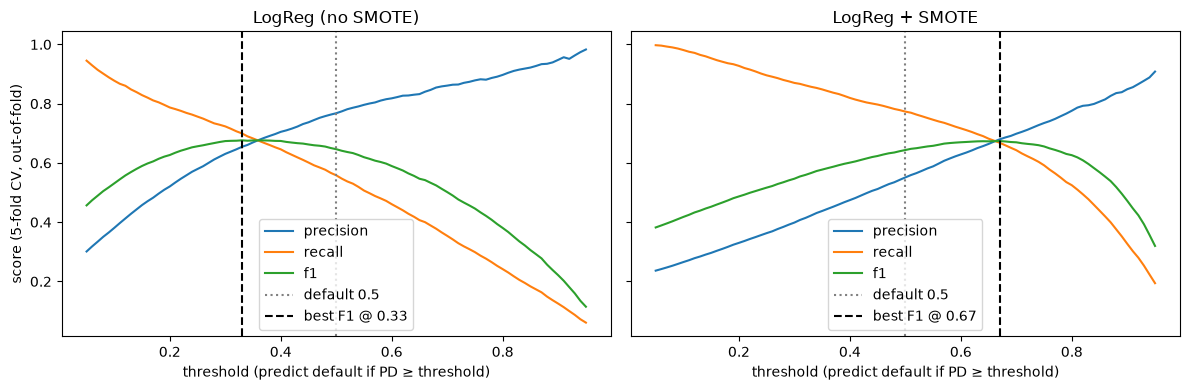

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

def sweep(proba, y):
    """Precision, recall and F1 at every cutoff."""
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        rows.append({"threshold": t,
                     "precision": precision_score(y, pred, zero_division=0),
                     "recall": recall_score(y, pred),
                     "f1": f1_score(y, pred)})
    return pd.DataFrame(rows).set_index("threshold")

# Out-of-fold PDs: each row is scored by the model from the round where it was in the validation fold
models = {"LogReg (no SMOTE)": logreg, "LogReg + SMOTE": logreg_smote}
oof_proba, sweeps, summary = {}, {}, []
for name, pipe in models.items():
    oof_proba[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    sweeps[name] = s = sweep(oof_proba[name], y_train)
    best_t = s["f1"].idxmax()
    summary.append({"model": name,
                    "F1 @ 0.50": round(s.loc[0.50, "f1"], 4),
                    "best threshold": best_t,
                    "precision @ best": round(s.loc[best_t, "precision"], 4),
                    "recall @ best": round(s.loc[best_t, "recall"], 4),
                    "F1 @ best": round(s.loc[best_t, "f1"], 4)})

summary = pd.DataFrame(summary).set_index("model")
print(summary)

# Plot precision / recall / F1 against the cutoff for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, s) in zip(axes, sweeps.items()):
    s.plot(ax=ax)
    best_t = summary.loc[name, "best threshold"]
    ax.axvline(0.5, color="grey", linestyle=":", label="default 0.5")
    ax.axvline(best_t, color="black", linestyle="--", label=f"best F1 @ {best_t:.2f}")
    ax.set_title(name)
    ax.set_xlabel("threshold (predict default if PD ≥ threshold)")
    ax.legend()
axes[0].set_ylabel("score (5-fold CV, out-of-fold)")
plt.tight_layout()
plt.show()

In [7]:
# Interactive cutoff explorer for logistic regression (with and without SMOTE).
# Uses the out-of-fold PDs from the cell above, so moving the slider does NOT retrain anything.
import ipywidgets as widgets
from IPython.display import display
from sklearn.metrics import accuracy_score

def explore_cutoff(cutoff):
    rows = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, (name, proba) in zip(axes, oof_proba.items()):
        pred = (proba >= cutoff).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
        rows.append({"model": name,
                     "accuracy": round(accuracy_score(y_train, pred), 4),
                     "precision": round(precision_score(y_train, pred, zero_division=0), 4),
                     "recall": round(recall_score(y_train, pred), 4),
                     "F1": round(f1_score(y_train, pred), 4),
                     "flagged as default": int(tp + fp),
                     "defaulters caught (TP)": int(tp), "defaulters missed (FN)": int(fn),
                     "good customers flagged (FP)": int(fp)})
        sweeps[name].plot(ax=ax)
        ax.axvline(summary.loc[name, "best threshold"], color="black", linestyle="--", label="best F1")
        ax.axvline(cutoff, color="red", linewidth=2, label=f"slider = {cutoff:.2f}")
        ax.set_title(name)
        ax.set_xlabel("cutoff (predict default if PD ≥ cutoff)")
        ax.legend(loc="lower left")
    axes[0].set_ylabel("score (5-fold CV, out-of-fold)")
    plt.tight_layout()
    plt.show()
    # astype(object) keeps the counts as whole numbers after transposing
    display(pd.DataFrame(rows).set_index("model").astype(object).T)

widgets.interact(
    explore_cutoff,
    cutoff=widgets.FloatSlider(value=0.50, min=0.05, max=0.95, step=0.01,
                               description="cutoff", readout_format=".2f",
                               continuous_update=False,   # update when you release the slider
                               layout=widgets.Layout(width="600px")),
);

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='cutoff', layout=Layout(widt…

## Step 5: Maximal margin classifier → soft-margin linear SVM

**Maximal margin (hard margin) classifier.** Find the flat hyperplane $w \cdot x + b = 0$ that separates defaulters ($y=+1$) from non-defaulters ($y=-1$) with the **widest possible gap** (margin width $= 2/\lVert w \rVert$):

$$\min_{w,b}\ \tfrac12\lVert w\rVert^2 \quad \text{s.t.}\quad y_i\,(w\cdot x_i + b) \ge 1 \ \text{ for every } i$$

This only works if the classes are **perfectly separable** by a flat boundary. Ours are not (two applicants with the same profile can have different outcomes), so a hard margin has no solution.

**Soft margin (support vector classifier).** Allow some points to sit inside the margin or on the wrong side, using a *slack* $\xi_i \ge 0$ for each point, and pay a penalty $C$ for it:

$$\min_{w,b,\xi}\ \tfrac12\lVert w\rVert^2 + C\sum_i \xi_i \quad \text{s.t.}\quad y_i\,(w\cdot x_i + b) \ge 1-\xi_i$$

| $C$ | Behaviour |
|---|---|
| **small** | slack is cheap → **wide margin**, many points inside it, smoother and more biased |
| **large** | slack is expensive → **narrow margin**, fits the training data tightly, more variance; as $C \to \infty$ it approaches the hard-margin classifier |

Only points **on or inside the margin** (the *support vectors*) determine the boundary.

The boundary is **linear**, like logistic regression; only the loss differs (hinge vs log-loss). Below, $C$ is chosen with 5-fold CV (same folds, preprocessing inside the pipeline, SMOTE only on the training folds). The default cutoff is the boundary itself (score 0).

`LinearSVC(loss="hinge")` solves exactly this problem and is much faster than `SVC(kernel="linear")` on 20,000+ rows.

Best C by mean 5-fold CV F1:
         C  precision  recall      f1  roc_auc   f1_sd
SMOTE                                                 
False  1.0     0.7699  0.5573  0.6464   0.8658  0.0077
True   1.0     0.5766  0.7598  0.6556   0.8668  0.0067


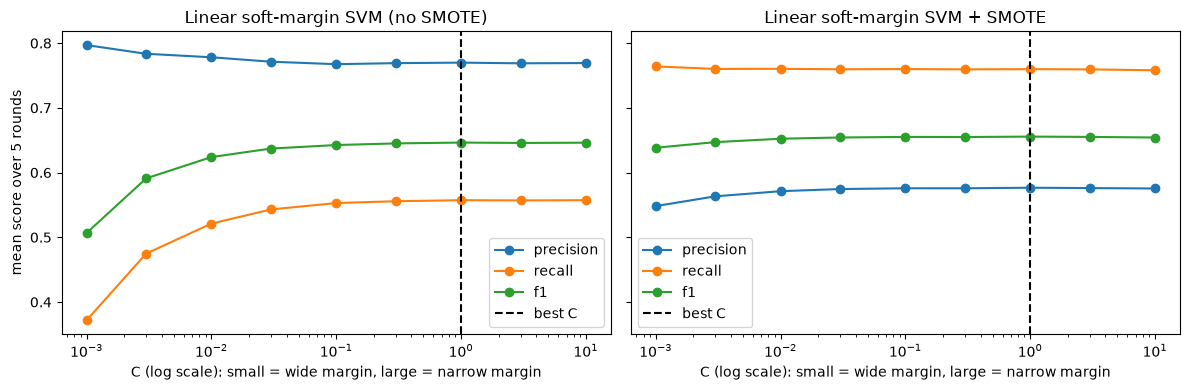

In [8]:
# Soft-margin linear SVM: sweep C with 5-fold CV and pick the C with the highest MEAN F1
import warnings
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning

def make_linear_svm(C, use_smote):
    steps = [("prep", preprocess)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000)))
    return ImbPipeline(steps)

C_grid = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]
sweep_metrics = ["precision", "recall", "f1", "roc_auc"]
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for use_smote in (False, True):
        for C in C_grid:
            r = cross_validate(make_linear_svm(C, use_smote), X_train, y_train,
                               cv=cv, scoring=sweep_metrics, n_jobs=5)
            rows.append({"SMOTE": use_smote, "C": C,
                         **{m: r[f"test_{m}"].mean() for m in sweep_metrics},
                         "f1_sd": r["test_f1"].std()})
lin_sweep = pd.DataFrame(rows)

# Best C = highest mean F1 across the 5 rounds, separately with and without SMOTE
best_C = lin_sweep.loc[lin_sweep.groupby("SMOTE")["f1"].idxmax()].set_index("SMOTE")
print("Best C by mean 5-fold CV F1:")
print(best_C.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (use_smote, g) in zip(axes, lin_sweep.groupby("SMOTE")):
    g.set_index("C")[["precision", "recall", "f1"]].plot(ax=ax, marker="o", logx=True)
    ax.axvline(best_C.loc[use_smote, "C"], color="black", linestyle="--", label="best C")
    ax.set_title(f"Linear soft-margin SVM {'+ SMOTE' if use_smote else '(no SMOTE)'}")
    ax.set_xlabel("C (log scale): small = wide margin, large = narrow margin")
    ax.legend()
axes[0].set_ylabel("mean score over 5 rounds")
plt.tight_layout()
plt.show()

In [9]:
# Interactive: choose C and SMOTE, then click "Run 5-fold CV" (this DOES retrain: 5 models per click).
# Shows per-round scores on the untouched validation folds, plus what C does to the margin itself.
lin_C = widgets.FloatLogSlider(value=float(best_C.loc[False, "C"]), base=10, min=-3, max=1, step=0.25,
                               description="C", readout_format=".3g", continuous_update=False,
                               layout=widgets.Layout(width="450px"))
lin_smote = widgets.Checkbox(value=False, description="use SMOTE (training folds only)")
lin_run = widgets.Button(description="Run 5-fold CV", button_style="primary", icon="play")
lin_out = widgets.Output()

def run_linear_cv(_):
    C, use_smote = lin_C.value, lin_smote.value
    with lin_out:
        lin_out.clear_output(wait=True)
        print(f"Running 5-fold CV with C = {C:.3g}, SMOTE = {use_smote} ...")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            r = cross_validate(make_linear_svm(C, use_smote), X_train, y_train, cv=cv,
                               scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
                               return_estimator=True, return_indices=True, n_jobs=5)
        rows = []
        for k, est in enumerate(r["estimator"]):
            train_idx = r["indices"]["train"][k]
            # Margin diagnostics on that round's ORIGINAL training rows (before any SMOTE)
            Xp = est.named_steps["prep"].transform(X_train.iloc[train_idx])
            f = est.named_steps["model"].decision_function(Xp)
            y_pm = 2 * y_train.iloc[train_idx].to_numpy() - 1          # 0/1 -> -1/+1
            w = est.named_steps["model"].coef_.ravel()
            rows.append({"round": k + 1,
                         **{m: r[f"test_{m}"][k] for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
                         "margin width 2/||w||": 2 / np.linalg.norm(w),
                         "% train pts on/inside margin": 100 * np.mean(y_pm * f <= 1),
                         "% train pts misclassified": 100 * np.mean(y_pm * f < 0)})
        t = pd.DataFrame(rows).set_index("round")
        t.loc["mean"] = t.mean()
        t.loc["sd"] = t.iloc[:5].std()
        lin_out.clear_output(wait=True)
        print(f"Linear soft-margin SVM, C = {C:.3g}, SMOTE = {use_smote}  (default cutoff = 0)")
        display(t.round(4))

lin_run.on_click(run_linear_cv)
display(widgets.VBox([widgets.HBox([lin_C, lin_smote]), lin_run, lin_out]))
run_linear_cv(None)   # show the best-C result straight away

## Step 6: Support Vector Machine with RBF kernel (candidate model)

**Idea.** Same soft-margin SVM as Step 5 (widest margin, slack penalised by C), but the boundary no longer has to be flat.

**RBF kernel.** The linear SVM in Step 5 is a flat cut through the 26 features. The RBF kernel measures similarity between two applicants as

$$K(x, x') = \exp\left(-\gamma \, \lVert x - x' \rVert^2\right)$$

so the SVM can draw **curved** boundaries, e.g. "high loan-to-income is risky, *unless* the applicant owns a home and has no past default".

**Hyperparameters** (defaults used here; tuned in a later step):
- `C = 1`: penalty for slack, exactly as in Step 5. Larger C means a tighter fit to the training data and more risk of overfitting.
- `gamma = "scale"`: how far each point's influence reaches. Larger gamma means more wiggly boundaries.

**Score, not probability.** `SVC` outputs a signed distance from the boundary (`decision_function`); its default cutoff is **0**. Getting probabilities needs an extra internal 5-fold calibration (about 5× slower), so we tune the cutoff on this score directly, using the same leak-free out-of-fold method as Step 4.

Same 5 folds, same preprocessing, SMOTE only inside the 4 training folds.

In [10]:
import time
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, roc_auc_score, precision_recall_curve

svm = Pipeline([
    ("prep", preprocess),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale")),
])
svm_smote = ImbPipeline([
    ("prep", preprocess),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale")),
])

def fold_metrics(score, y, cutoff):
    """Per-round metrics from out-of-fold scores, at a given cutoff (score >= cutoff -> default)."""
    rows = []
    for k, (_, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
        s, yv = score[val_idx], y.iloc[val_idx]
        pred = (s >= cutoff).astype(int)
        rows.append({"round": k, "accuracy": accuracy_score(yv, pred),
                     "precision": precision_score(yv, pred, zero_division=0),
                     "recall": recall_score(yv, pred), "f1": f1_score(yv, pred),
                     "roc_auc": roc_auc_score(yv, s)})
    t = pd.DataFrame(rows).set_index("round")
    t.loc["mean"] = t.mean()
    return t.round(4)

def f1_curve(score, y):
    """Precision, recall and F1 at EVERY distinct score.
    F1 can only change when the cutoff crosses an actual score, so these are all the cutoffs that matter.
    Uses the same rule as everywhere else: predict default if score >= cutoff."""
    precision, recall, thresholds = precision_recall_curve(y, score)
    p, r = precision[:-1], recall[:-1]          # last point (p=1, r=0) has no threshold
    f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
    return pd.DataFrame({"precision": p, "recall": r, "f1": f1}, index=pd.Index(thresholds, name="cutoff"))

def best_cutoff(score, y):
    """Exact search: the cutoff with the highest F1 over every distinct score (no range or grid to choose)."""
    curve = f1_curve(score, y)
    return float(curve["f1"].idxmax())

svm_scores, svm_summary = {}, []
for name, pipe in {"SVM RBF (no SMOTE)": svm, "SVM RBF + SMOTE": svm_smote}.items():
    start = time.time()
    # One out-of-fold score per training row, from the 5 rounds (n_jobs=5 runs the rounds in parallel)
    svm_scores[name] = s = cross_val_predict(pipe, X_train, y_train, cv=cv,
                                             method="decision_function", n_jobs=5)
    print(f"{name}: 5 rounds in {time.time() - start:.0f}s")

    at_default = fold_metrics(s, y_train, cutoff=0.0)
    cut = best_cutoff(s, y_train)
    at_best = fold_metrics(s, y_train, cutoff=cut)
    print(f"  per-round metrics at the default cutoff 0:\n{at_default}\n")
    svm_summary.append({"model": name,
                        "F1 @ default": at_default.loc["mean", "f1"],
                        "best cutoff": round(cut, 3),
                        "precision @ best": at_best.loc["mean", "precision"],
                        "recall @ best": at_best.loc["mean", "recall"],
                        "F1 @ best": at_best.loc["mean", "f1"],
                        "roc_auc": at_default.loc["mean", "roc_auc"]})

# Compare with tuned logistic regression (Step 4)
logreg_rows = [{"model": n, "F1 @ default": summary.loc[n, "F1 @ 0.50"],
                "best cutoff": summary.loc[n, "best threshold"],
                "precision @ best": summary.loc[n, "precision @ best"],
                "recall @ best": summary.loc[n, "recall @ best"],
                "F1 @ best": summary.loc[n, "F1 @ best"],
                "roc_auc": round(roc_auc_score(y_train, oof_proba[n]), 4)} for n in summary.index]
leaderboard = pd.DataFrame(logreg_rows + svm_summary).set_index("model")
print("Leaderboard (5-fold CV, out-of-fold):")
leaderboard

SVM RBF (no SMOTE): 5 rounds in 27s
  per-round metrics at the default cutoff 0:
       accuracy  precision  recall      f1  roc_auc
round                                              
1        0.9121     0.9302  0.6464  0.7627   0.8994
2        0.9150     0.9392  0.6534  0.7707   0.9019
3        0.9124     0.9370  0.6429  0.7626   0.8968
4        0.9099     0.9133  0.6499  0.7594   0.8947
5        0.9119     0.9215  0.6526  0.7641   0.8977
mean     0.9123     0.9282  0.6490  0.7639   0.8981



SVM RBF + SMOTE: 5 rounds in 1198s


  per-round metrics at the default cutoff 0:
       accuracy  precision  recall      f1  roc_auc
round                                              
1        0.8928     0.7656  0.7346  0.7498   0.9097
2        0.8926     0.7551  0.7531  0.7541   0.9103
3        0.8957     0.7703  0.7451  0.7575   0.9088
4        0.8839     0.7297  0.7451  0.7373   0.9025
5        0.8870     0.7412  0.7425  0.7419   0.9058
mean     0.8904     0.7524  0.7441  0.7481   0.9074

Leaderboard (5-fold CV, out-of-fold):


,F1 @ default,best cutoff,precision @ best,recall @ best,F1 @ best,roc_auc
model,,,,,,
LogReg (no SMOTE),0.6463,0.330,0.6543,0.6996,0.6762,0.8688
LogReg + SMOTE,0.6435,0.670,0.6796,0.6681,0.6738,0.8697
SVM RBF (no SMOTE),0.7639,-0.189,0.8897,0.6751,0.7677,0.8981
SVM RBF + SMOTE,0.7481,0.431,0.8652,0.6854,0.7648,0.9074


### Step 6b: Interactive RBF explorer (C and gamma)

Choose **C**, **gamma** and SMOTE, then click **Run 5-fold CV**. Each click trains 5 RBF SVMs on the same folds as before (SMOTE only on the training folds). Every run is added to a history table, sorted by validation F1.

What to look at:
- **Validation F1** (mean ± sd over the 5 rounds) is what we choose hyperparameters by.
- **Train F1 vs validation F1.** A large gap means **overfitting**: the boundary is memorising the training folds. Expect this for large gamma and large C.
- **% support vectors.** The share of training points on or inside the margin. Small gamma and small C mean a softer, smoother model; very large gamma makes almost every point a support vector because each one only influences its own tiny neighbourhood.

| | small | large |
|---|---|---|
| **C** | wide, forgiving margin (more bias) | narrow margin, fits training data tightly (more variance) |
| **gamma** | each point influences a wide area → smooth, almost linear boundary (underfits) | influence is very local → wiggly boundary that wraps around single points (overfits) |

⏱ Roughly 1–1.5 min per click without SMOTE at moderate settings, 2–4× longer with SMOTE. Large gamma combined with large C is the slowest (sliders are capped at C ≈ 31.6 and gamma = 1 for that reason).

In [11]:
# Interactive RBF SVM explorer: C, gamma, SMOTE -> 5-fold CV (retrains 5 models per click)
import scipy.sparse as sp

def make_rbf_svm(C, gamma, use_smote):
    steps = [("prep", preprocess)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", SVC(kernel="rbf", C=C, gamma=gamma)))
    return ImbPipeline(steps)

# What gamma="scale" (the default used above) works out to on our 26 preprocessed features
_Xp = clone(preprocess).fit_transform(X_train)
_Xp = _Xp.toarray() if sp.issparse(_Xp) else _Xp
gamma_scale = 1.0 / (_Xp.shape[1] * _Xp.var())
print(f'gamma="scale" = 1 / (n_features x variance) = {gamma_scale:.4f}  (slider starts here)')

# Ranges are capped (C <= ~31.6, gamma <= 1): beyond that a single click can take 5-10 minutes
rbf_C = widgets.FloatLogSlider(value=1.0, base=10, min=-1, max=1.5, step=0.25, description="C",
                               readout_format=".3g", continuous_update=False,
                               layout=widgets.Layout(width="420px"))
rbf_gamma = widgets.FloatLogSlider(value=round(gamma_scale, 4), base=10, min=-3, max=0, step=0.25,
                                   description="gamma", readout_format=".3g", continuous_update=False,
                                   layout=widgets.Layout(width="420px"))
rbf_smote = widgets.Checkbox(value=False, description="use SMOTE (training folds only)")
rbf_run = widgets.Button(description="Run 5-fold CV", button_style="primary", icon="play")
rbf_out = widgets.Output()
rbf_history = []   # every run you make is recorded here for comparison

def run_rbf_cv(_):
    C, gamma, use_smote = rbf_C.value, rbf_gamma.value, rbf_smote.value
    with rbf_out:
        rbf_out.clear_output(wait=True)
        print(f"Running 5-fold CV: C = {C:.3g}, gamma = {gamma:.3g}, SMOTE = {use_smote} ...")
        start = time.time()
        r = cross_validate(make_rbf_svm(C, gamma, use_smote), X_train, y_train, cv=cv,
                           scoring=["precision", "recall", "f1", "roc_auc"],
                           return_train_score=True, return_estimator=True, n_jobs=5)
        rows = []
        for k, est in enumerate(r["estimator"]):
            svc = est.named_steps["model"]
            # share of the rows the SVM was fit on (incl. SMOTE rows if used) that became support vectors
            pct_sv = 100 * svc.n_support_.sum() / svc.shape_fit_[0]
            rows.append({"round": k + 1,
                         "val precision": r["test_precision"][k], "val recall": r["test_recall"][k],
                         "val F1": r["test_f1"][k], "val ROC-AUC": r["test_roc_auc"][k],
                         "train F1": r["train_f1"][k],
                         "F1 gap (train - val)": r["train_f1"][k] - r["test_f1"][k],
                         "% support vectors": pct_sv})
        t = pd.DataFrame(rows).set_index("round")
        t.loc["mean"] = t.mean()
        t.loc["sd"] = t.iloc[:5].std()
        rbf_history.append({"C": C, "gamma": round(gamma, 4), "SMOTE": use_smote,
                            "val F1 mean": t.loc["mean", "val F1"], "val F1 sd": t.loc["sd", "val F1"],
                            "train F1 mean": t.loc["mean", "train F1"],
                            "% SV": t.loc["mean", "% support vectors"],
                            "seconds": round(time.time() - start)})
        rbf_out.clear_output(wait=True)
        print(f"RBF SVM, C = {C:.3g}, gamma = {gamma:.3g}, SMOTE = {use_smote}  "
              f"(default cutoff 0, {time.time() - start:.0f}s)")
        display(t.round(4))
        print("\nAll runs so far (best validation F1 first):")
        display(pd.DataFrame(rbf_history).sort_values("val F1 mean", ascending=False)
                .reset_index(drop=True).round(4))

rbf_run.on_click(run_rbf_cv)
display(widgets.VBox([widgets.HBox([rbf_C, rbf_gamma]), rbf_smote, rbf_run, rbf_out]))

gamma="scale" = 1 / (n_features x variance) = 0.0963  (slider starts here)


### Step 6c: Automatic tuning of C and gamma (subset search → full confirmation)

A full grid search on all 25,927 training rows would take a long time (an RBF SVM's training time grows roughly with the square of the number of rows). So we tune in two stages, **using only the training set**:

1. **Search on a subset.** Draw a stratified sample of 8,000 training rows (same 22% default rate). Run `GridSearchCV` over every combination of C × gamma with 5-fold stratified CV on that subset, and rank the combinations by **mean validation F1**. This is cheap and shows *where* the good region is.
2. **Confirm on the full training set.** Take the top 2 combinations from each recipe and evaluate them with our **original 5 folds on all 25,927 rows**, next to the default (C = 1, gamma = scale). The final choice is made from these full-data scores.

Why confirm? The best settings can shift with more data (more rows can support a more complex boundary, i.e. larger C or gamma), so the subset only narrows the search; it does not make the final decision.

The test set is still untouched.

subset: 8000 rows, default rate 0.2188
24 combinations x 5 folds per recipe



SVM RBF (no SMOTE): searched in 72s. Top 5 by mean validation F1 (subset):
    C  gamma  mean F1  sd F1  rank_test_score
100.0   0.03   0.7648 0.0156                1
 30.0   0.03   0.7646 0.0122                2
 10.0   0.10   0.7594 0.0145                3
  3.0   0.10   0.7578 0.0135                4
 10.0   0.03   0.7564 0.0139                5
  EDGE SVM RBF (no SMOTE): best C = 100 is on the edge, but it beats the best interior setting (C = 30) by only 0.0002 < 1 SD (0.0156) -> plateau, extending the grid is unlikely to help
  OK   SVM RBF (no SMOTE): best gamma = 0.03 is inside the grid



SVM RBF + SMOTE: searched in 136s. Top 5 by mean validation F1 (subset):
    C  gamma  mean F1  sd F1  rank_test_score
100.0   0.01   0.7308 0.0065                1
 30.0   0.03   0.7294 0.0076                2
 10.0   0.03   0.7280 0.0080                3
100.0   0.03   0.7255 0.0054                4
  1.0   0.10   0.7203 0.0103                5
  EDGE SVM RBF + SMOTE: best C = 100 is on the edge, but it beats the best interior setting (C = 30) by only 0.0015 < 1 SD (0.0065) -> plateau, extending the grid is unlikely to help
  EDGE SVM RBF + SMOTE: best gamma = 0.01 is on the edge, but it beats the best interior setting (gamma = 0.03) by only 0.0015 < 1 SD (0.0065) -> plateau, extending the grid is unlikely to help



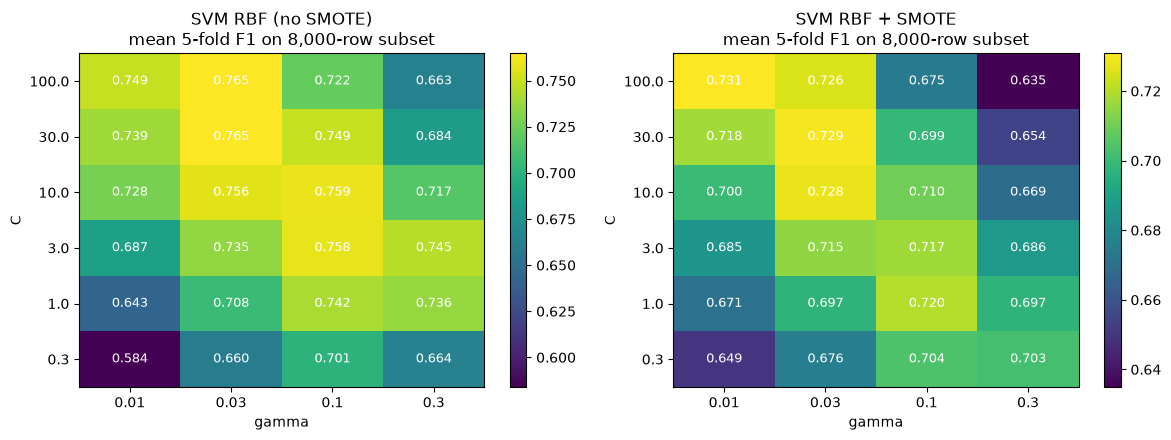

In [12]:
# Stage 1: grid search over C x gamma on a stratified 8,000-row subset of the TRAINING set
from sklearn.model_selection import GridSearchCV, train_test_split

X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=8000,
                                      stratify=y_train, random_state=RANDOM_STATE)
cv_sub = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"subset: {len(X_sub)} rows, default rate {y_sub.mean():.4f}")

# Log-spaced grid centred on the default (C = 1, gamma = scale ~ 0.096).
# C = 100 was added after the first run put the SMOTE winner on the edge (C = 30).
param_grid = {"model__C": [0.3, 1, 3, 10, 30, 100],
              "model__gamma": [0.01, 0.03, 0.1, 0.3]}
print(f"{len(param_grid['model__C']) * len(param_grid['model__gamma'])} combinations x 5 folds per recipe\n")

def edge_check(name, res):
    """Is the winner on the boundary of the grid? If so, is it clearly better than the best
    combination strictly inside the grid, or only by less than one fold-to-fold SD (a plateau)?"""
    best = res.iloc[0]
    for label, col, grid in [("C", "C", param_grid["model__C"]),
                             ("gamma", "gamma", param_grid["model__gamma"])]:
        value = float(best[col])
        if value not in (min(grid), max(grid)):
            print(f"  OK   {name}: best {label} = {value:g} is inside the grid")
            continue
        inside = res[~res[col].astype(float).isin([min(grid), max(grid)])].iloc[0]
        gain = best["mean F1"] - inside["mean F1"]
        if gain < best["sd F1"]:
            print(f"  EDGE {name}: best {label} = {value:g} is on the edge, but it beats the best interior "
                  f"setting ({label} = {float(inside[col]):g}) by only {gain:.4f} < 1 SD ({best['sd F1']:.4f}) "
                  f"-> plateau, extending the grid is unlikely to help")
        else:
            print(f"  EDGE {name}: best {label} = {value:g} is on the edge and beats the interior by {gain:.4f} "
                  f"(> 1 SD) -> extend the grid in that direction")

subset_results = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, use_smote) in zip(axes, [("SVM RBF (no SMOTE)", False), ("SVM RBF + SMOTE", True)]):
    start = time.time()
    search = GridSearchCV(make_rbf_svm(1.0, "scale", use_smote), param_grid,
                          cv=cv_sub, scoring="f1", n_jobs=-1)
    search.fit(X_sub, y_sub)
    res = pd.DataFrame(search.cv_results_)
    res = res.rename(columns={"param_model__C": "C", "param_model__gamma": "gamma",
                              "mean_test_score": "mean F1", "std_test_score": "sd F1"})
    res = res[["C", "gamma", "mean F1", "sd F1", "rank_test_score"]].sort_values("rank_test_score")
    subset_results[name] = res
    print(f"{name}: searched in {time.time() - start:.0f}s. Top 5 by mean validation F1 (subset):")
    print(res.head(5).round(4).to_string(index=False))
    edge_check(name, res)
    print()

    heat = res.pivot(index="C", columns="gamma", values="mean F1").astype(float)
    im = ax.imshow(heat.values, cmap="viridis", aspect="auto", origin="lower")
    ax.set_xticks(range(len(heat.columns)), heat.columns)
    ax.set_yticks(range(len(heat.index)), heat.index)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            ax.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
    ax.set_xlabel("gamma"); ax.set_ylabel("C")
    ax.set_title(f"{name}\nmean 5-fold F1 on 8,000-row subset")
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [13]:
# Stage 2: confirm the top-2 subset candidates per recipe on the FULL training set (original 5 folds),
# next to the untuned default (C = 1, gamma = scale). Final choice = highest mean validation F1 here.
candidates = []
for name, use_smote in [("SVM RBF (no SMOTE)", False), ("SVM RBF + SMOTE", True)]:
    candidates.append((name, use_smote, 1.0, gamma_scale, "default"))
    for _, row in subset_results[name].head(2).iterrows():
        candidates.append((name, use_smote, float(row["C"]), float(row["gamma"]),
                           f"subset rank {int(row['rank_test_score'])}"))

confirm_rows = []
for name, use_smote, C, gamma, source in candidates:
    start = time.time()
    r = cross_validate(make_rbf_svm(C, gamma, use_smote), X_train, y_train, cv=cv,
                       scoring=["precision", "recall", "f1", "roc_auc"], n_jobs=5)
    confirm_rows.append({"recipe": name, "C": C, "gamma": round(gamma, 4), "source": source,
                         "precision": r["test_precision"].mean(), "recall": r["test_recall"].mean(),
                         "mean F1": r["test_f1"].mean(), "sd F1": r["test_f1"].std(),
                         "roc_auc": r["test_roc_auc"].mean(),
                         "seconds": round(time.time() - start)})
    print(f"{name:<20} C={C:<5g} gamma={gamma:<7.4g} ({source:<14}) mean F1 = {r['test_f1'].mean():.4f}"
          f"   [{time.time() - start:.0f}s]")

confirm = pd.DataFrame(confirm_rows)
rbf_best = confirm.loc[confirm.groupby("recipe")["mean F1"].idxmax()].set_index("recipe")
print("\nFull training set, original 5 folds (default cutoff 0):")
display(confirm.round(4))
print("Chosen C and gamma per recipe (highest mean validation F1 on the full training set):")
display(rbf_best[["C", "gamma", "source", "mean F1", "sd F1", "precision", "recall", "roc_auc"]].round(4))

SVM RBF (no SMOTE)   C=1     gamma=0.0963  (default       ) mean F1 = 0.7639   [35s]


SVM RBF (no SMOTE)   C=100   gamma=0.03    (subset rank 1 ) mean F1 = 0.7824   [53s]


SVM RBF (no SMOTE)   C=30    gamma=0.03    (subset rank 2 ) mean F1 = 0.7764   [40s]


SVM RBF + SMOTE      C=1     gamma=0.0963  (default       ) mean F1 = 0.7485   [108s]


SVM RBF + SMOTE      C=100   gamma=0.01    (subset rank 1 ) mean F1 = 0.7485   [145s]


SVM RBF + SMOTE      C=30    gamma=0.03    (subset rank 2 ) mean F1 = 0.7573   [118s]

Full training set, original 5 folds (default cutoff 0):


,recipe,C,gamma,source,precision,recall,mean F1,sd F1,roc_auc,seconds
0,SVM RBF (no SMOTE),1.0,0.0963,default,0.9282,0.6490,0.7639,0.0037,0.8981,35
1,SVM RBF (no SMOTE),100.0,0.0300,subset rank 1,0.9306,0.6750,0.7824,0.0047,0.9058,53
2,SVM RBF (no SMOTE),30.0,0.0300,subset rank 2,0.9287,0.6670,0.7764,0.0038,0.9041,40
3,SVM RBF + SMOTE,1.0,0.0963,default,0.7532,0.7441,0.7485,0.0076,0.9074,108
4,SVM RBF + SMOTE,100.0,0.0100,subset rank 1,0.7546,0.7425,0.7485,0.0063,0.9061,145
5,SVM RBF + SMOTE,30.0,0.0300,subset rank 2,0.7795,0.7365,0.7573,0.0069,0.9080,118


Chosen C and gamma per recipe (highest mean validation F1 on the full training set):


,C,gamma,source,mean F1,sd F1,precision,recall,roc_auc
recipe,,,,,,,,
SVM RBF (no SMOTE),100.0,0.03,subset rank 1,0.7824,0.0047,0.9306,0.6750,0.9058
SVM RBF + SMOTE,30.0,0.03,subset rank 2,0.7573,0.0069,0.7795,0.7365,0.9080


### Step 6d: Cutoff tuning for the tuned RBF SVMs

Step 6c chose C and gamma at the **default cutoff (0)**. Now, with those values fixed, we tune the cutoff:

1. `cross_val_predict(..., method="decision_function")` → one **out-of-fold** score per training row (same 5 folds).
2. **Exact search over every possible cutoff.** F1 can only change when the cutoff crosses an actual score, so the only cutoffs that matter are the observed scores themselves. `precision_recall_curve` computes precision and recall at **all** of them at once (about 25,000 cutoffs), so there is no range or grid to choose and nothing between grid points can be missed.
3. **Graph:** precision, recall and F1 against the cutoff, marking the default (0), the best cutoff, and each fold's own best cutoff. It shows whether the peak is sharp or a broad plateau, and whether the "best" is a stable region or a noisy spike.
4. **Per-fold check:** does the tuned cutoff beat 0 in every round, and is each fold's own best cutoff close to it?

Done for both recipes (no SMOTE and + SMOTE), each with its own best C and gamma from Step 6c. The cutoff is frozen for the final test-set evaluation.

SVM RBF (no SMOTE)  (C = 100, gamma = 0.03)  -- 5 rounds in 48s, 25927 distinct cutoffs checked


,F1 @ 0,F1 @ -0.143 (pooled best),fold's own best cutoff,F1 @ own best
round,,,,
1,0.7760,0.7774,-0.3095,0.7801
2,0.7904,0.7950,-0.0776,0.7959
3,0.7822,0.7873,-0.3000,0.7921
4,0.7828,0.7799,0.0068,0.7832
5,0.7805,0.7830,-0.1406,0.7830
mean,0.7824,0.7845,-0.1642,0.7869
sd,0.0052,0.0069,0.1386,0.0068


  tuned cutoff beats 0 in 4 of 5 rounds



SVM RBF + SMOTE  (C = 30, gamma = 0.03)  -- 5 rounds in 89s, 25927 distinct cutoffs checked


,F1 @ 0,F1 @ 0.397 (pooled best),fold's own best cutoff,F1 @ own best
round,,,,
1,0.7546,0.7648,0.4254,0.7664
2,0.7627,0.7865,0.4055,0.7882
3,0.7678,0.7780,0.5038,0.7793
4,0.7489,0.7628,0.3944,0.7634
5,0.7526,0.7719,0.3993,0.7722
mean,0.7573,0.7728,0.4257,0.7739
sd,0.0077,0.0097,0.0452,0.0100


  tuned cutoff beats 0 in 5 of 5 rounds



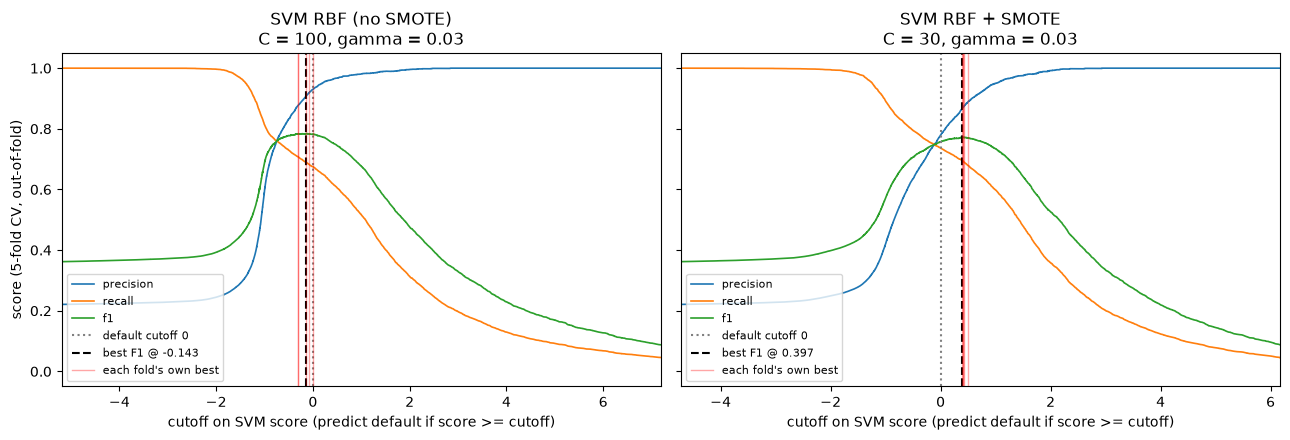

Leaderboard (5-fold CV, out-of-fold; sorted by F1 at the tuned cutoff):


,F1 @ default,best cutoff,precision @ best,recall @ best,F1 @ best,roc_auc
model,,,,,,
"SVM RBF (no SMOTE), tuned C=100, gamma=0.03",0.7824,-0.143,0.9084,0.6905,0.7845,0.9058
"SVM RBF + SMOTE, tuned C=30, gamma=0.03",0.7573,0.397,0.8683,0.6963,0.7728,0.9080
SVM RBF (no SMOTE),0.7639,-0.189,0.8897,0.6751,0.7677,0.8981
SVM RBF + SMOTE,0.7481,0.431,0.8652,0.6854,0.7648,0.9074
LogReg (no SMOTE),0.6463,0.330,0.6543,0.6996,0.6762,0.8688
LogReg + SMOTE,0.6435,0.670,0.6796,0.6681,0.6738,0.8697


In [14]:
# Cutoff tuning for the tuned RBF SVMs (C and gamma from Step 6c, fixed here)
# best_cutoff / f1_curve (Step 6) evaluate F1 at EVERY distinct out-of-fold score -> exact, no grid.
rbf_tuned_scores, rbf_tuned_cutoff, rbf_fold_cutoffs, tuned_rows = {}, {}, {}, []
for name, use_smote in [("SVM RBF (no SMOTE)", False), ("SVM RBF + SMOTE", True)]:
    C, gamma = float(rbf_best.loc[name, "C"]), float(rbf_best.loc[name, "gamma"])
    start = time.time()
    # Out-of-fold scores: each row scored by the model from the round where it was in the validation fold
    s = cross_val_predict(make_rbf_svm(C, gamma, use_smote), X_train, y_train, cv=cv,
                          method="decision_function", n_jobs=5)
    rbf_tuned_scores[name] = s
    cut = best_cutoff(s, y_train)
    rbf_tuned_cutoff[name] = cut
    at_default, at_best = fold_metrics(s, y_train, 0.0), fold_metrics(s, y_train, cut)
    print(f"{name}  (C = {C:g}, gamma = {gamma:g})  -- 5 rounds in {time.time() - start:.0f}s, "
          f"{len(f1_curve(s, y_train))} distinct cutoffs checked")

    # Per-fold check: F1 at 0 vs at the pooled best cutoff, and each fold's own (exact) best cutoff
    check, own_cuts = [], []
    for k, (_, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
        sv, yv = s[val_idx], y_train.iloc[val_idx]
        own = best_cutoff(sv, yv)
        own_cuts.append(own)
        check.append({"round": k,
                      "F1 @ 0": f1_score(yv, (sv >= 0).astype(int)),
                      f"F1 @ {cut:.3f} (pooled best)": f1_score(yv, (sv >= cut).astype(int)),
                      "fold's own best cutoff": own,
                      "F1 @ own best": f1_score(yv, (sv >= own).astype(int))})
    rbf_fold_cutoffs[name] = own_cuts
    check = pd.DataFrame(check).set_index("round")
    check.loc["mean"] = check.mean()
    check.loc["sd"] = check.iloc[:5].std()
    beats = int((check.iloc[:5, 1] > check.iloc[:5, 0]).sum())
    display(check.round(4))
    print(f"  tuned cutoff beats 0 in {beats} of 5 rounds\n")

    tuned_rows.append({"model": f"{name}, tuned C={C:g}, gamma={gamma:g}",
                       "F1 @ default": at_default.loc["mean", "f1"],
                       "best cutoff": round(cut, 3),
                       "precision @ best": at_best.loc["mean", "precision"],
                       "recall @ best": at_best.loc["mean", "recall"],
                       "F1 @ best": at_best.loc["mean", "f1"],
                       "roc_auc": at_default.loc["mean", "roc_auc"]})

# Graph: precision / recall / F1 at every cutoff, for both recipes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (name, s) in zip(axes, rbf_tuned_scores.items()):
    curve = f1_curve(s, y_train)
    curve.plot(ax=ax, linewidth=1.2)
    cut = rbf_tuned_cutoff[name]
    ax.axvline(0, color="grey", linestyle=":", label="default cutoff 0")
    ax.axvline(cut, color="black", linestyle="--", label=f"best F1 @ {cut:.3f}")
    for i, c in enumerate(rbf_fold_cutoffs[name]):
        ax.axvline(c, color="red", alpha=0.35, linewidth=1, label="each fold's own best" if i == 0 else None)
    ax.set_xlim(*np.percentile(s, [1, 99]))   # zoom for readability only; the search used every cutoff
    ax.set_title(f"{name}\nC = {rbf_best.loc[name, 'C']:g}, gamma = {rbf_best.loc[name, 'gamma']:g}")
    ax.set_xlabel("cutoff on SVM score (predict default if score >= cutoff)")
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("score (5-fold CV, out-of-fold)")
plt.tight_layout()
plt.show()

# Updated leaderboard: every model at its own tuned cutoff (linear SVM from Step 5 not cutoff-tuned)
leaderboard_tuned = pd.concat([leaderboard, pd.DataFrame(tuned_rows).set_index("model")])
print("Leaderboard (5-fold CV, out-of-fold; sorted by F1 at the tuned cutoff):")
display(leaderboard_tuned.sort_values("F1 @ best", ascending=False).round(4))